# Lab 8: Soil Moisture Predicting System (Kaggle Version)

**Mục tiêu:** Tiền xử lý dữ liệu cảm biến IoT từ hai trạm đo (`user1_data` và `user2_data`), hợp nhất dữ liệu theo khung thời gian 5 phút, xử lý khuyết thiếu (Standard Imputation & Extended Imputation) và so sánh hiệu năng các mô hình học máy (**Random Forest Regressor**, **RFR Pipeline**, **XGBoost Regressor**) để dự đoán độ ẩm đất (`sm`).

# 1. Imports & Environment Setup

In [42]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 100
print('All libraries imported successfully!')

All libraries imported successfully!


# 2. Load Data (Kaggle Dataset)

In [43]:
def find_csv_on_kaggle(patterns):
    # Ưu tiên đường dẫn chuẩn trên Kaggle Input
    for p in patterns:
        if os.path.exists(p):
            return p
    # Tự động tìm kiếm đệ quy trong /kaggle/input hoặc thư mục hiện tại
    for base_dir in ['/kaggle/input', '.']:
        if os.path.exists(base_dir):
            for p in patterns:
                fname = os.path.basename(p)
                matches = glob.glob(os.path.join(base_dir, '**', fname), recursive=True)
                if matches:
                    return matches[0]
    raise FileNotFoundError(f'Không tìm thấy file dữ liệu trong danh sách: {patterns}')

path1 = find_csv_on_kaggle([
    '/kaggle/input/datasets/dungtnnguyen/iot-toi/user1_data-1.csv',
])
path2 = find_csv_on_kaggle([
    '/kaggle/input/datasets/dungtnnguyen/iot-toi/user2_data-1.csv',
])

data1 = pd.read_csv(path1)
data2 = pd.read_csv(path2)

print(f'Loaded data1 from: {path1} -> shape = {data1.shape}')
print(f'Loaded data2 from: {path2} -> shape = {data2.shape}')

Loaded data1 from: /kaggle/input/datasets/dungtnnguyen/iot-toi/user1_data-1.csv -> shape = (19341, 8)
Loaded data2 from: /kaggle/input/datasets/dungtnnguyen/iot-toi/user2_data-1.csv -> shape = (20166, 10)


# 3. Data Visualization & Exploratory Analysis (EDA)

In [44]:
print('data1 columns:', data1.columns.tolist())
print('data1 shape:', data1.shape)
print('data2 columns:', data2.columns.tolist())
print('data2 shape:', data2.shape)

display(data1.head())
display(data1.tail())

data1 columns: ['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'st', 'lum']
data1 shape: (19341, 8)
data2 columns: ['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'lum', 'temp', 'humd', 'pres']
data2 shape: (20166, 10)


,ttime,pm1,pm2,pm3,am,sm,st,lum
0,2022-07-18 15:42:55,3.63,0.0,0.0,3.2,7813.0,25.65,15001.0
1,2022-07-18 15:47:55,4.19,0.0,0.0,4.8,7692.0,25.66,13863.0
2,2022-07-18 15:52:55,4.74,0.0,0.0,4.0,7813.0,25.67,13788.0
3,2022-07-18 15:57:55,5.30,0.0,0.0,4.8,7813.0,25.68,14383.0
4,2022-07-18 16:02:55,0.55,5.3,5.3,3.2,7813.0,25.69,14621.0


,ttime,pm1,pm2,pm3,am,sm,st,lum
19336,2023-03-10 08:45:06,1.11,1.11,28.49,3.2,291.0,29.40,384.0
19337,2023-03-10 09:12:06,0.55,1.11,28.49,3.2,292.0,29.32,384.0
19338,2023-03-10 09:39:09,1.11,1.11,28.49,2.4,291.0,29.24,384.0
19339,2023-03-10 10:06:09,0.55,1.11,28.49,1.6,291.0,29.17,384.0
19340,2023-03-10 11:01:05,0.55,1.11,28.49,8.8,292.0,29.06,384.0


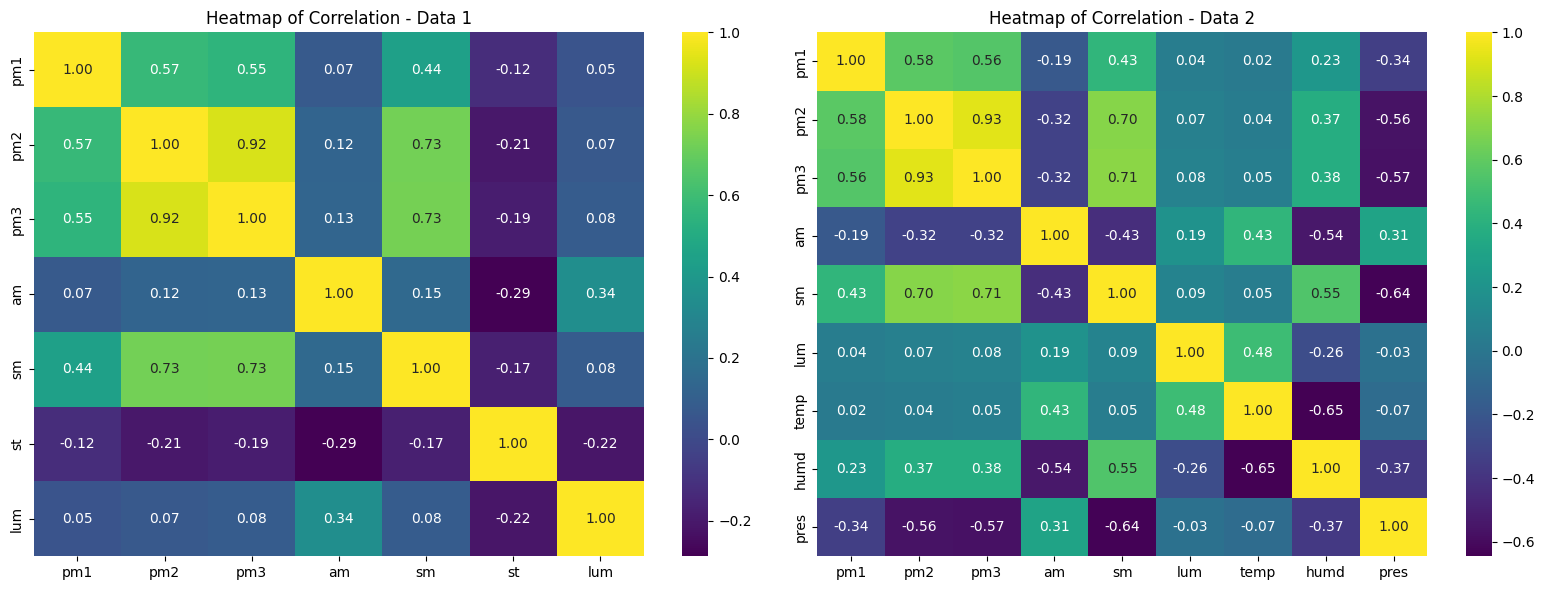

In [45]:
# Ma trận tương quan của data1 và data2 (dùng numeric_only=True để tránh lỗi cột chuỗi ttime)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(data1.corr(numeric_only=True), annot=True, fmt='.2f', cmap='viridis', ax=axes[0])
axes[0].set_title('Heatmap of Correlation - Data 1')

sns.heatmap(data2.corr(numeric_only=True), annot=True, fmt='.2f', cmap='viridis', ax=axes[1])
axes[1].set_title('Heatmap of Correlation - Data 2')

plt.tight_layout()
plt.show()

# 4. Data Pre-Processing

In [46]:
# Trích xuất đặc trưng thời gian cho data1 và gom nhóm theo khung 5 phút
data1['ttime'] = pd.to_datetime(data1['ttime'], format='%Y-%m-%d %H:%M:%S')
data1.set_index('ttime', inplace=True)
data1['day'] = data1.index.day
data1['Month'] = data1.index.month
data1['year'] = data1.index.year
data1['hour'] = data1.index.hour
data1['min'] = (data1.index.minute // 5) + 1
data1.reset_index(inplace=True)
data1 = data1.drop(columns=['ttime'])

display(data1.head())

,pm1,pm2,pm3,am,sm,st,lum,day,Month,year,hour,min
0,3.63,0.0,0.0,3.2,7813.0,25.65,15001.0,18,7,2022,15,9
1,4.19,0.0,0.0,4.8,7692.0,25.66,13863.0,18,7,2022,15,10
2,4.74,0.0,0.0,4.0,7813.0,25.67,13788.0,18,7,2022,15,11
3,5.30,0.0,0.0,4.8,7813.0,25.68,14383.0,18,7,2022,15,12
4,0.55,5.3,5.3,3.2,7813.0,25.69,14621.0,18,7,2022,16,1


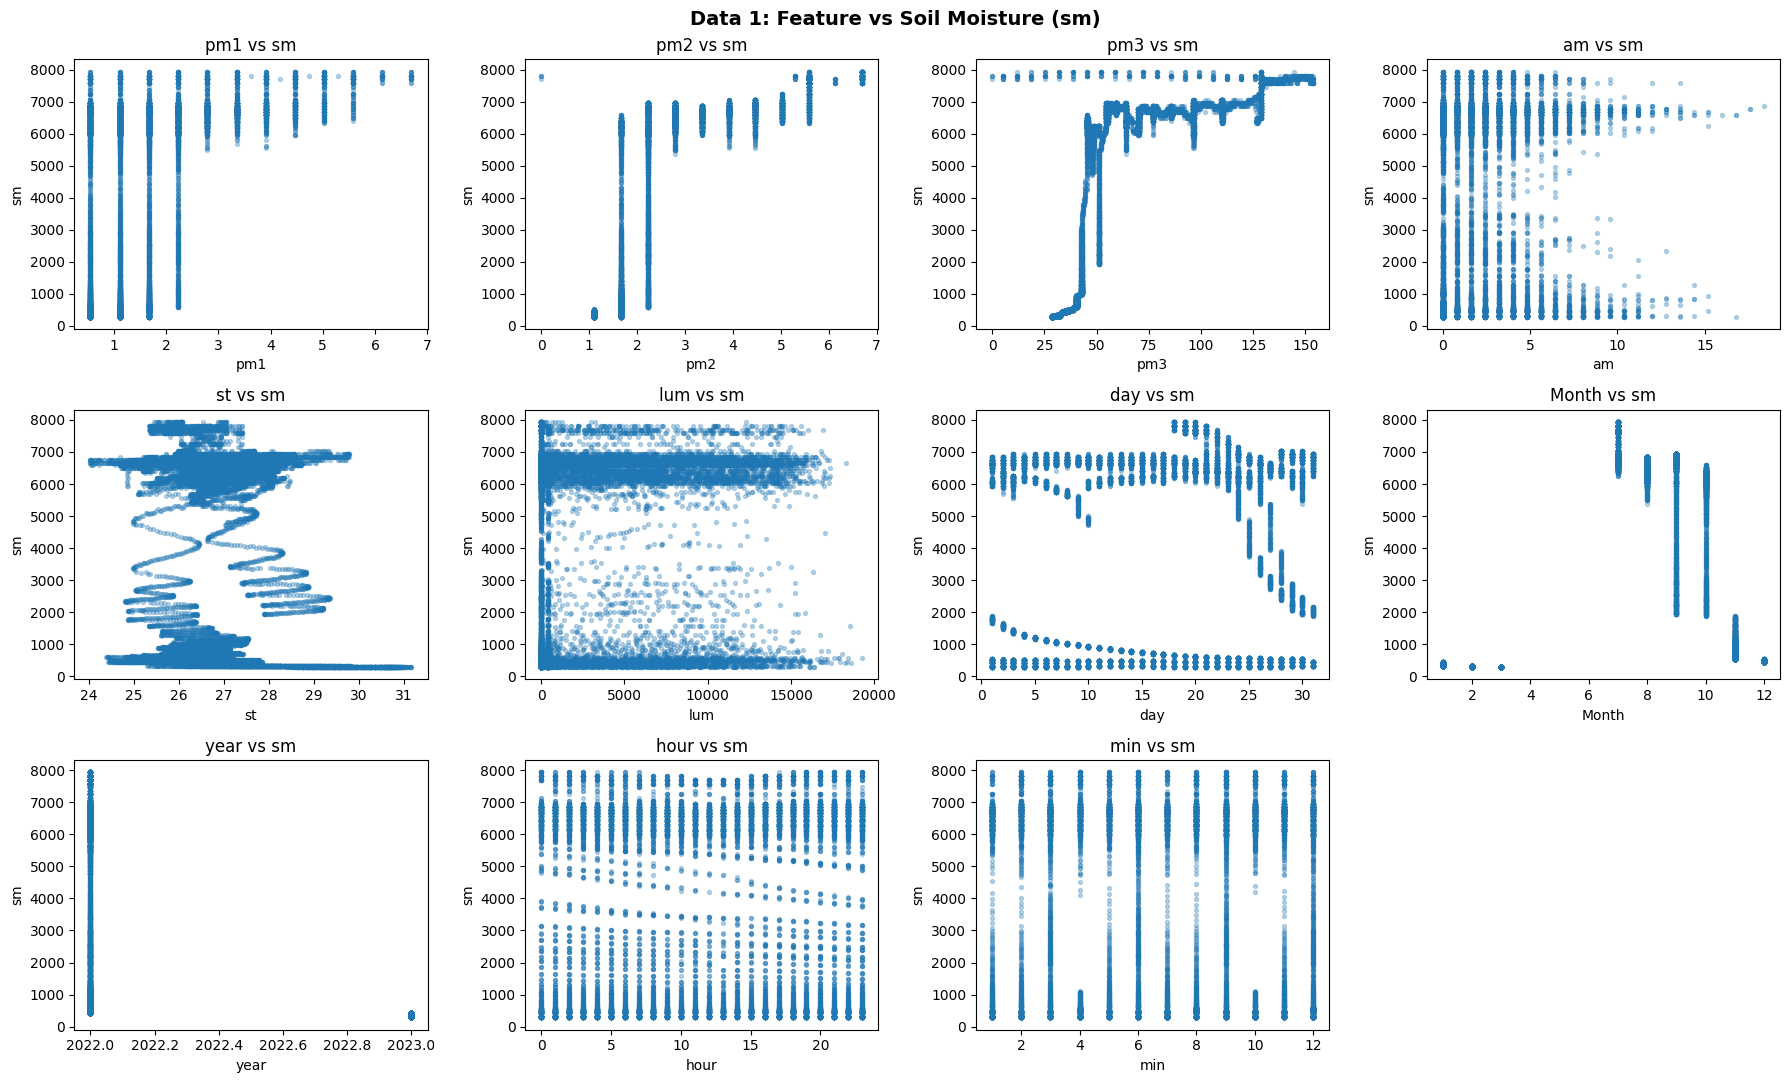

In [47]:
# Biểu đồ phân tán giữa các đặc trưng của data1 với độ ẩm đất (sm)
cols_d1 = [c for c in data1.columns if c != 'sm']
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.flatten()

for idx, col in enumerate(cols_d1):
    axes[idx].scatter(data1[col], data1['sm'], alpha=0.3, s=8, color='#1f77b4')
    axes[idx].set_title(f'{col} vs sm')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('sm')

for idx in range(len(cols_d1), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Data 1: Feature vs Soil Moisture (sm)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [48]:
# Trích xuất đặc trưng thời gian cho data2 và gom nhóm theo khung 5 phút
data2['ttime'] = pd.to_datetime(data2['ttime'], format='%Y-%m-%d %H:%M:%S')
data2.set_index('ttime', inplace=True)
data2['day'] = data2.index.day
data2['Month'] = data2.index.month
data2['year'] = data2.index.year
data2['hour'] = data2.index.hour
data2['min'] = (data2.index.minute // 5) + 1
data2.reset_index(inplace=True)
data2 = data2.drop(columns=['ttime'])

display(data2.head())

,pm1,pm2,pm3,am,sm,lum,temp,humd,pres,day,Month,year,hour,min
0,0.83,0.00,0.00,0.0,7463.0,6547.0,23.02,90.57,92849.25,18,7,2022,15,8
1,1.39,0.00,0.00,0.0,7576.0,10249.0,23.47,88.37,92848.31,18,7,2022,15,9
2,1.95,0.00,0.00,0.0,7576.0,12636.0,23.64,85.26,92844.82,18,7,2022,15,10
3,2.51,0.00,0.00,0.0,7463.0,8318.0,23.62,85.93,92834.94,18,7,2022,15,11
4,0.55,2.51,2.51,0.0,7463.0,4149.0,23.82,86.06,92815.25,18,7,2022,15,12


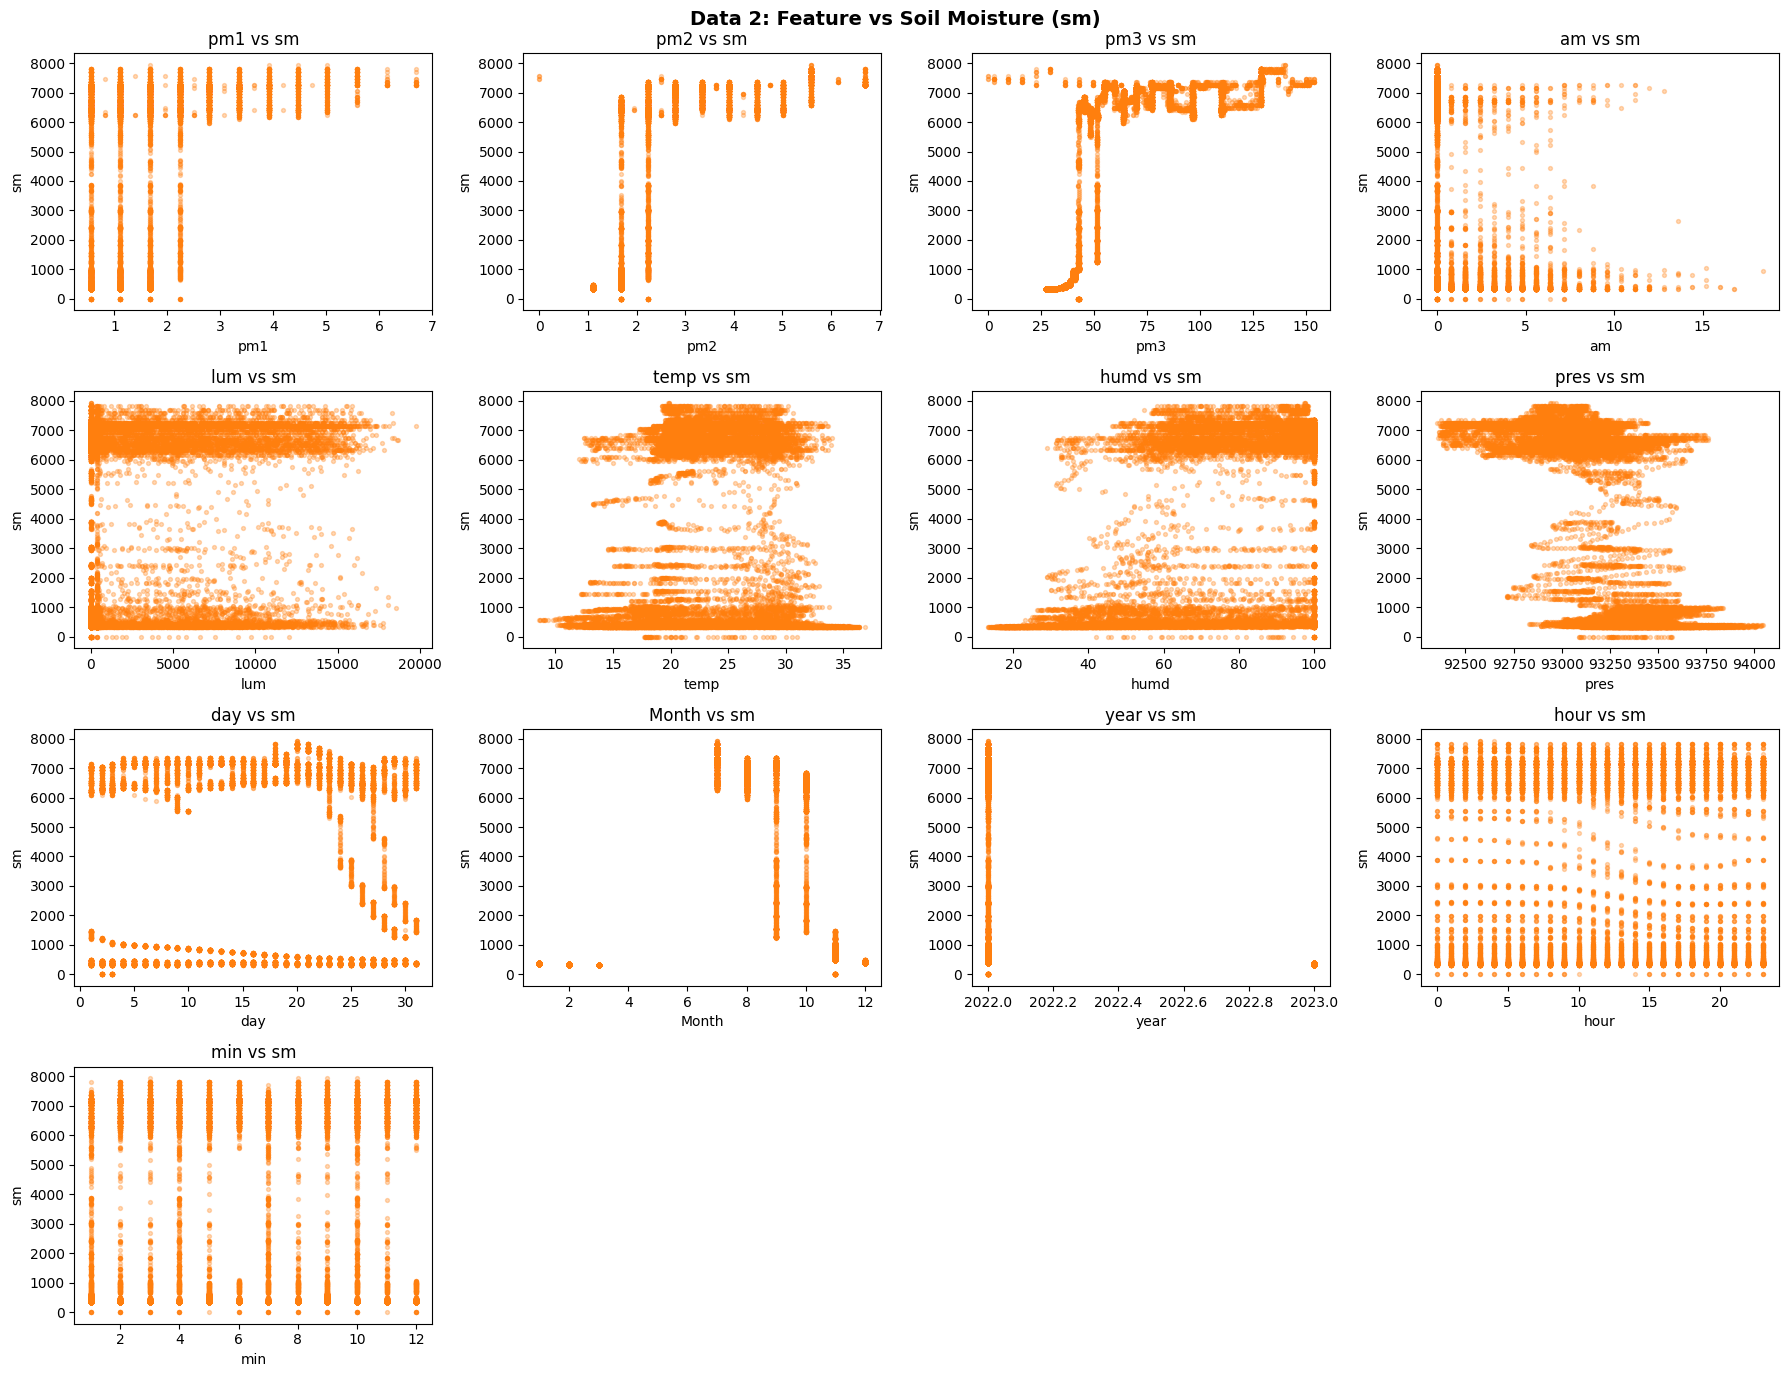

In [49]:
# Biểu đồ phân tán giữa các đặc trưng của data2 với độ ẩm đất (sm)
cols_d2 = [c for c in data2.columns if c != 'sm']
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for idx, col in enumerate(cols_d2):
    axes[idx].scatter(data2[col], data2['sm'], alpha=0.3, s=8, color='#ff7f0e')
    axes[idx].set_title(f'{col} vs sm')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('sm')

for idx in range(len(cols_d2), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Data 2: Feature vs Soil Moisture (sm)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Combine Data (Data Fusion)

In [50]:
# Ghép nối data1 và data2 theo khóa thời gian (day, Month, year, hour, min)
data_comb = data1.merge(data2, on=['day', 'Month', 'year', 'hour', 'min'], how='outer')
print('Shape before merging duplicate columns:', data_comb.shape)
print('Count of missing values before merging columns:\n', data_comb.isnull().sum())

# Hợp nhất các cặp cột đo chung (_x và _y) bằng trung bình theo hàng
shared_features = ['pm1', 'pm2', 'pm3', 'am', 'sm', 'lum']
cols_to_drop = []

for feat in shared_features:
    pair = [f'{feat}_x', f'{feat}_y']
    data_comb[feat] = data_comb[pair].mean(axis=1)
    cols_to_drop.extend(pair)

data_comb = data_comb.drop(columns=cols_to_drop)

print('\nShape after merging duplicate columns:', data_comb.shape)
print('Missing values after merging:\n', data_comb.isnull().sum())
display(data_comb.head())
display(data_comb.describe())

# Lưu file tổng hợp ra thư mục làm việc của Kaggle
data_comb.to_csv('/kaggle/working/data_comb-2.csv', index=False)

Shape before merging duplicate columns: (33038, 21)
Count of missing values before merging columns:
 pm1_x    13697
pm2_x    13697
pm3_x    13697
am_x     13697
sm_x     13697
st       13697
lum_x    13697
day          0
Month        0
year         0
hour         0
min          0
pm1_y    12872
pm2_y    12872
pm3_y    12872
am_y     12872
sm_y     12872
lum_y    12872
temp     12872
humd     12872
pres     12872
dtype: int64

Shape after merging duplicate columns: (33038, 15)
Missing values after merging:
 st       13697
day          0
Month        0
year         0
hour         0
min          0
temp     12872
humd     12872
pres     12872
pm1          0
pm2          0
pm3          0
am           0
sm           0
lum          0
dtype: int64


,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
0,NaN,1,1,2023,0,1,17.03,92.56,93737.36,0.55,1.11,33.52,0.0,373.0,4.0
1,27.49,1,1,2023,0,5,16.72,94.43,93718.07,0.83,1.39,33.52,0.0,401.5,2.0
2,27.45,1,1,2023,0,9,NaN,NaN,NaN,1.11,1.67,33.52,0.0,431.0,1.0
3,NaN,1,1,2023,0,10,16.69,94.27,93694.30,1.67,1.11,33.52,0.0,373.0,3.0
4,27.40,1,1,2023,1,2,16.79,91.79,93670.49,0.55,1.39,33.52,0.0,401.5,2.0


,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
count,19341.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000,20166.000000,20166.000000,20166.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000
mean,26.852714,16.203644,8.086809,2022.162994,11.527998,6.505388,22.625972,78.329035,93154.619405,1.534521,2.476357,57.103645,1.383715,4122.373524,2795.742206
std,1.163759,9.026522,3.128060,0.369366,6.992460,3.456231,4.666760,24.007034,290.963485,0.976174,1.183368,26.138342,2.090352,3007.643883,4166.394793
min,24.040000,1.000000,1.000000,2022.000000,0.000000,1.000000,8.610000,13.320000,92352.450000,0.550000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.110000,8.000000,7.000000,2022.000000,5.000000,4.000000,20.000000,61.690000,92976.272500,0.550000,1.670000,36.880000,0.000000,474.000000,1.000000
50%,26.700000,17.000000,9.000000,2022.000000,12.000000,6.000000,21.430000,88.220000,93152.930000,1.110000,2.230000,48.330000,0.000000,6173.000000,47.500000
75%,27.390000,24.000000,10.000000,2022.000000,18.000000,9.000000,26.110000,100.000000,93350.997500,2.230000,3.350000,70.400000,2.400000,6757.000000,4991.375000
max,31.170000,31.000000,12.000000,2023.000000,23.000000,12.000000,36.880000,100.000000,94042.780000,6.700000,6.700000,153.660000,18.390000,7937.000000,19767.000000


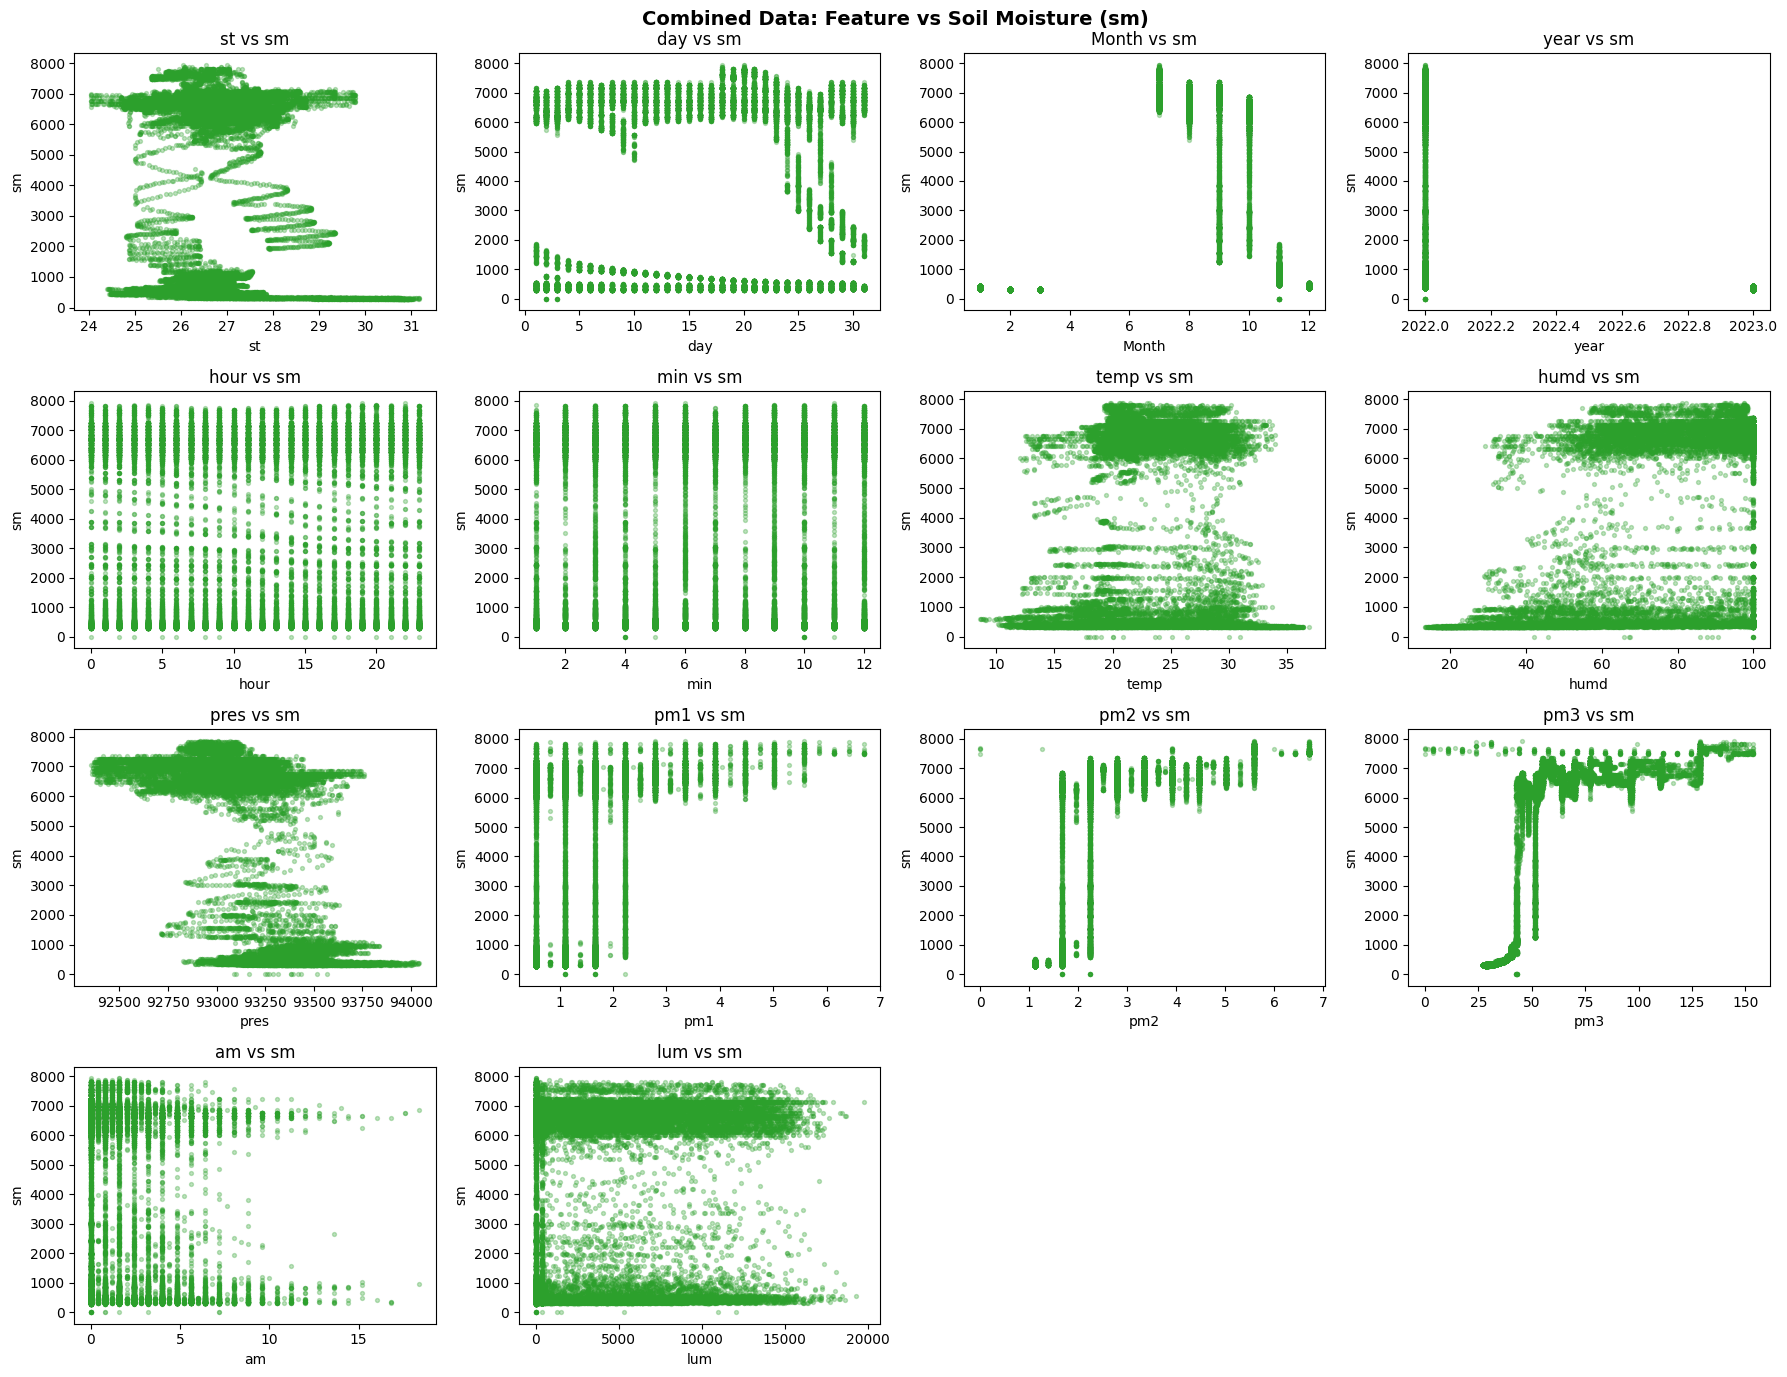

In [51]:
# Biểu đồ phân tán trên tập dữ liệu tổng hợp data_comb
cols_comb = [c for c in data_comb.columns if c != 'sm']
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for idx, col in enumerate(cols_comb):
    axes[idx].scatter(data_comb[col], data_comb['sm'], alpha=0.3, s=8, color='#2ca02c')
    axes[idx].set_title(f'{col} vs sm')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('sm')

for idx in range(len(cols_comb), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Combined Data: Feature vs Soil Moisture (sm)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 6. Model Preparation & Imputation Setup

In [52]:
if 'Unnamed: 0' in data_comb.columns:
    data_comb = data_comb.drop(columns=['Unnamed: 0'])

X = data_comb.drop(columns=['sm'])
y = data_comb['sm']

# Chia tập Train (80%) và Validation (20%)
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, train_size=0.8, test_size=0.2, random_state=32
)

# --- Chiến lược 1: Standard Imputation (điền khuyết bằng giá trị trung bình) ---
my_imputer = SimpleImputer(strategy='mean')
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train), columns=X_train.columns)
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid), columns=X_valid.columns)

# --- Chiến lược 2: Extended Imputation (thêm cột cờ *_was_missing trước khi điền khuyết) ---
X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()

cols_with_missing = [col for col in X_train.columns if X_train[col].isnull().any()]
print('Columns with missing values:', cols_with_missing)

for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()

my_imputer_plus = SimpleImputer(strategy='mean')
imputed_X_train_plus = pd.DataFrame(my_imputer_plus.fit_transform(X_train_plus), columns=X_train_plus.columns)
imputed_X_valid_plus = pd.DataFrame(my_imputer_plus.transform(X_valid_plus), columns=X_valid_plus.columns)

print(f'X_train shape: {imputed_X_train.shape} | X_train_plus shape: {imputed_X_train_plus.shape}')

Columns with missing values: ['st', 'temp', 'humd', 'pres']
X_train shape: (26430, 14) | X_train_plus shape: (26430, 18)


# 7. Train & Evaluate Models
Huấn luyện và đánh giá đầy đủ 6 cấu hình mô hình:
1. **RFR Imputation**
2. **RFR An Extension to Imputation**
3. **RFR Pipeline Imputation**
4. **RFR Pipeline An Extension to Imputation**
5. **XGBoost Imputation**
6. **XGBoost An Extension to Imputation**

In [53]:
results_list = []
predictions_dict = {}

def evaluate_and_log(model_name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    results_list.append({
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2_Score': r2
    })
    predictions_dict[model_name] = y_pred
    print(f'=== {model_name} ===')
    print(f'MSE      : {mse:.4f}')
    print(f'RMSE     : {rmse:.4f}')
    print(f'MAE      : {mae:.4f}')
    print(f'R2 Score : {r2:.6f}\n')

In [54]:
# 7.1 Random Forest Regressor - Standard Imputation
rfr_imp = RandomForestRegressor(n_estimators=1000, criterion='squared_error', random_state=1, n_jobs=-1)
rfr_imp.fit(imputed_X_train, y_train)
evaluate_and_log('RFR Imputation', y_valid, rfr_imp.predict(imputed_X_valid))

# 7.2 Random Forest Regressor - Extended Imputation
rfr_ext = RandomForestRegressor(n_estimators=1000, criterion='squared_error', random_state=1, n_jobs=-1)
rfr_ext.fit(imputed_X_train_plus, y_train)
evaluate_and_log('RFR Extension to Imputation', y_valid, rfr_ext.predict(imputed_X_valid_plus))

=== RFR Imputation ===
MSE      : 13670.0321
RMSE     : 116.9189
MAE      : 39.4067
R2 Score : 0.998489

=== RFR Extension to Imputation ===
MSE      : 13536.7077
RMSE     : 116.3474
MAE      : 38.0946
R2 Score : 0.998503



In [55]:
# 7.3 RFR Pipeline - Standard Imputation
pipe_imp = Pipeline(steps=[
    ('preprocessor', SimpleImputer(strategy='mean')),
    ('model', RandomForestRegressor(n_estimators=1000, random_state=32, n_jobs=-1))
])
pipe_imp.fit(imputed_X_train, y_train)
evaluate_and_log('RFR Pipeline Imputation', y_valid, pipe_imp.predict(imputed_X_valid))

# 7.4 RFR Pipeline - Extended Imputation
pipe_ext = Pipeline(steps=[
    ('preprocessor', SimpleImputer(strategy='mean')),
    ('model', RandomForestRegressor(n_estimators=1000, random_state=32, n_jobs=-1))
])
pipe_ext.fit(imputed_X_train_plus, y_train)
evaluate_and_log('RFR Pipeline Extension to Imputation', y_valid, pipe_ext.predict(imputed_X_valid_plus))

=== RFR Pipeline Imputation ===
MSE      : 13688.9383
RMSE     : 116.9997
MAE      : 39.2745
R2 Score : 0.998486

=== RFR Pipeline Extension to Imputation ===
MSE      : 13424.5298
RMSE     : 115.8643
MAE      : 38.0553
R2 Score : 0.998516



In [56]:
# 7.5 XGBoost - Standard Imputation
xgb_imp = XGBRegressor(n_estimators=1000, learning_rate=0.05, early_stopping_rounds=5, n_jobs=4, random_state=32)
xgb_imp.fit(imputed_X_train, y_train, eval_set=[(imputed_X_valid, y_valid)], verbose=False)
evaluate_and_log('XGBoost Imputation', y_valid, xgb_imp.predict(imputed_X_valid))

# 7.6 XGBoost - Extended Imputation
xgb_ext = XGBRegressor(n_estimators=1000, learning_rate=0.05, early_stopping_rounds=5, n_jobs=4, random_state=32)
xgb_ext.fit(imputed_X_train_plus, y_train, eval_set=[(imputed_X_valid_plus, y_valid)], verbose=False)
evaluate_and_log('XGBoost Extension to Imputation', y_valid, xgb_ext.predict(imputed_X_valid_plus))

=== XGBoost Imputation ===
MSE      : 17821.6326
RMSE     : 133.4977
MAE      : 55.6060
R2 Score : 0.998029

=== XGBoost Extension to Imputation ===
MSE      : 18539.7266
RMSE     : 136.1607
MAE      : 58.0168
R2 Score : 0.997950



# 8. Compare Results & Select Best Model

,Model,MAE,MSE,RMSE,R2_Score
Rank,,,,,
1,RFR Pipeline Extension to Imputation,38.055278,13424.529818,115.864273,0.998516
2,RFR Extension to Imputation,38.094559,13536.707731,116.347358,0.998503
3,RFR Pipeline Imputation,39.274545,13688.938262,116.999736,0.998486
4,RFR Imputation,39.406660,13670.032078,116.918912,0.998489
5,XGBoost Imputation,55.605976,17821.632577,133.497688,0.998029
6,XGBoost Extension to Imputation,58.016800,18539.726624,136.160665,0.997950


>>> BEST MODEL: RFR Pipeline Extension to Imputation (MAE = 38.0553, R2 = 0.998516)


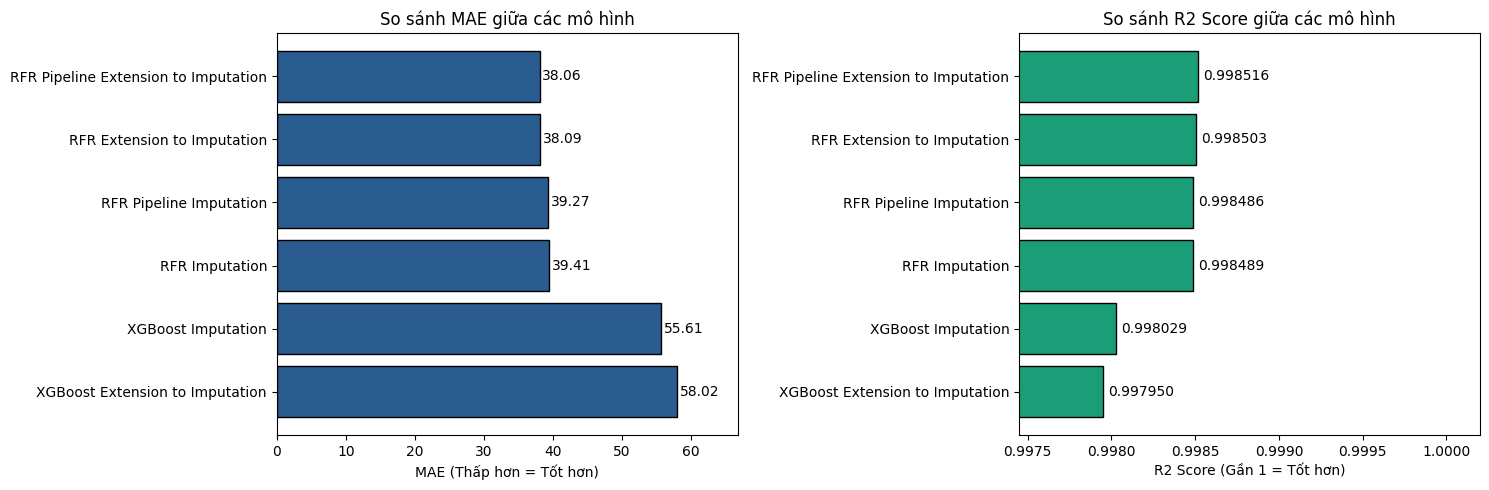

In [57]:
results_df = pd.DataFrame(results_list).sort_values(by='MAE', ascending=True).reset_index(drop=True)
results_df.index = results_df.index + 1
results_df.index.name = 'Rank'
display(results_df)

best_model_name = results_df.iloc[0]['Model']
best_preds = predictions_dict[best_model_name]
print(f'>>> BEST MODEL: {best_model_name} (MAE = {results_df.iloc[0]["MAE"]:.4f}, R2 = {results_df.iloc[0]["R2_Score"]:.6f})')

# Biểu đồ so sánh MAE và R2 Score giữa các mô hình
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].barh(results_df['Model'], results_df['MAE'], color='#2b5c8f', edgecolor='black')
axes[0].invert_yaxis()
axes[0].set_xlabel('MAE (Thấp hơn = Tốt hơn)')
axes[0].set_title('So sánh MAE giữa các mô hình')
for i, v in enumerate(results_df['MAE']):
    axes[0].text(v + 0.4, i, f'{v:.2f}', va='center')
axes[0].set_xlim(0, max(results_df['MAE']) * 1.15)

axes[1].barh(results_df['Model'], results_df['R2_Score'], color='#1b9e77', edgecolor='black')
axes[1].invert_yaxis()
axes[1].set_xlabel('R2 Score (Gần 1 = Tốt hơn)')
axes[1].set_title('So sánh R2 Score giữa các mô hình')
axes[1].set_xlim(min(results_df['R2_Score']) - 0.0005, 1.0002)
for i, v in enumerate(results_df['R2_Score']):
    axes[1].text(v + 0.00003, i, f'{v:.6f}', va='center')

plt.tight_layout()
plt.show()

# 9. Detailed Evaluation & Visualization (Best Model)

,Actual (sm),Predicted (sm),Residual,Absolute Error
0,6757.0,6783.0360,-26.0360,26.0360
1,6454.0,6623.7525,-169.7525,169.7525
2,499.0,498.3885,0.6115,0.6115
3,450.5,446.2325,4.2675,4.2675
4,371.0,370.1010,0.8990,0.8990
5,861.0,861.1360,-0.1360,0.1360
6,6623.0,6686.2040,-63.2040,63.2040
7,7047.5,7033.6110,13.8890,13.8890
8,7047.5,7035.3445,12.1555,12.1555
9,332.0,331.7880,0.2120,0.2120


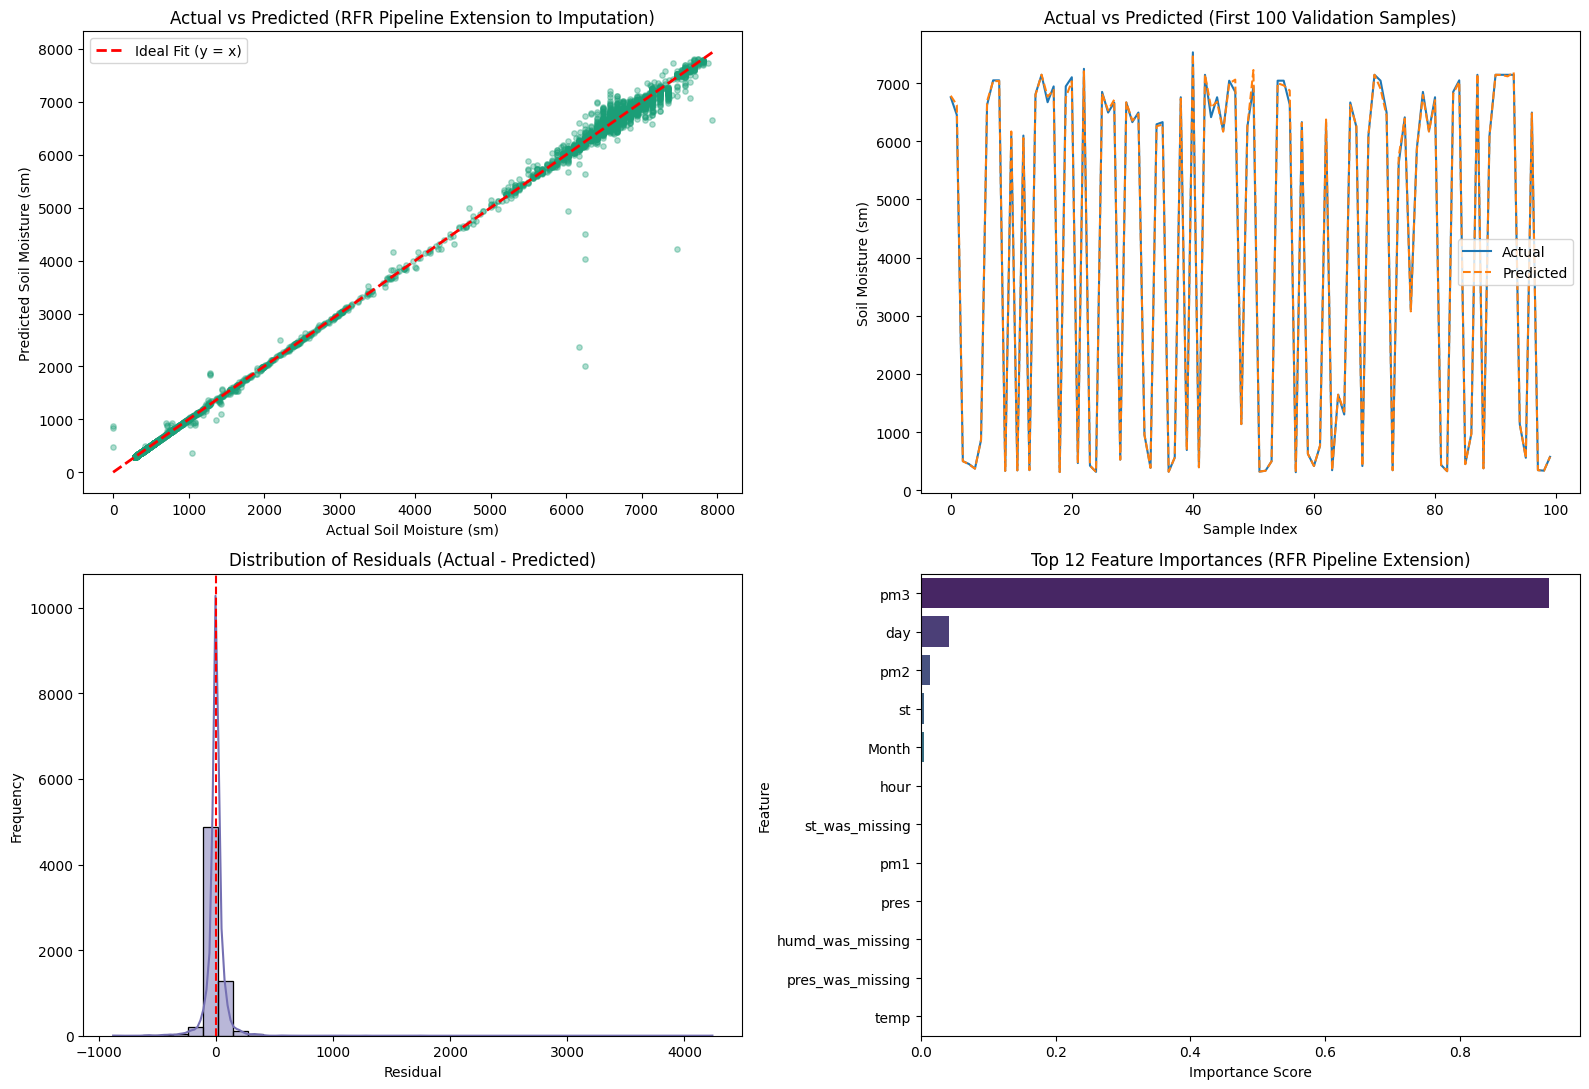

,Feature,Importance,Percentage (%)
11,pm3,9.315014e-01,93.150
1,day,4.182164e-02,4.182
10,pm2,1.338093e-02,1.338
0,st,4.306687e-03,0.431
2,Month,4.162062e-03,0.416
4,hour,1.195533e-03,0.120
14,st_was_missing,8.679947e-04,0.087
9,pm1,4.683614e-04,0.047
8,pres,3.955684e-04,0.040
16,humd_was_missing,3.597813e-04,0.036


In [58]:
# Bảng đối chiếu 10 mẫu đầu tiên trên tập kiểm định
residuals = y_valid.values - best_preds
abs_errors = np.abs(residuals)

comparison_df = pd.DataFrame({
    'Actual (sm)': y_valid.values,
    'Predicted (sm)': np.round(best_preds, 4),
    'Residual': np.round(residuals, 4),
    'Absolute Error': np.round(abs_errors, 4)
})
display(comparison_df.head(10))

# Dashboard 2x2 trực quan hóa đánh giá mô hình tốt nhất
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Scatter Actual vs Predicted
axes[0, 0].scatter(y_valid, best_preds, alpha=0.35, s=15, color='#1b9e77')
min_val = min(y_valid.min(), best_preds.min())
max_val = max(y_valid.max(), best_preds.max())
axes[0, 0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Fit (y = x)')
axes[0, 0].set_title(f'Actual vs Predicted ({best_model_name})')
axes[0, 0].set_xlabel('Actual Soil Moisture (sm)')
axes[0, 0].set_ylabel('Predicted Soil Moisture (sm)')
axes[0, 0].legend()

# 2. Line plot trên 100 mẫu đầu tiên
n_show = min(100, len(y_valid))
axes[0, 1].plot(range(n_show), y_valid.values[:n_show], label='Actual', lw=1.5)
axes[0, 1].plot(range(n_show), best_preds[:n_show], label='Predicted', linestyle='--', lw=1.5)
axes[0, 1].set_title(f'Actual vs Predicted (First {n_show} Validation Samples)')
axes[0, 1].set_xlabel('Sample Index')
axes[0, 1].set_ylabel('Soil Moisture (sm)')
axes[0, 1].legend()

# 3. Phân phối phần dư (Residuals)
sns.histplot(residuals, bins=40, kde=True, color='#7570b3', ax=axes[1, 0])
axes[1, 0].axvline(0, color='red', linestyle='--', lw=1.5)
axes[1, 0].set_title('Distribution of Residuals (Actual - Predicted)')
axes[1, 0].set_xlabel('Residual')
axes[1, 0].set_ylabel('Frequency')

# 4. Feature Importances (từ RFR Pipeline Extension)
rf_estimator = pipe_ext.named_steps['model']
feat_imp = pd.DataFrame({
    'Feature': imputed_X_train_plus.columns,
    'Importance': rf_estimator.feature_importances_
}).sort_values(by='Importance', ascending=False)

sns.barplot(data=feat_imp.head(12), x='Importance', y='Feature', palette='viridis', ax=axes[1, 1])
axes[1, 1].set_title('Top 12 Feature Importances (RFR Pipeline Extension)')
axes[1, 1].set_xlabel('Importance Score')
axes[1, 1].set_ylabel('Feature')

plt.tight_layout()
plt.show()

feat_imp['Percentage (%)'] = (feat_imp['Importance'] * 100).round(3)
display(feat_imp)